In [22]:
# Walk up to repo root (identified by README.md)
.root <- getwd()
while (!file.exists(file.path(.root, 'README.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(data.table)
  library(arrow)
  library(ggthemes)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = "white", color = NA),
    plot.background   = element_rect(fill = "white", color = NA),
    legend.background = element_rect(fill = "white", color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = "bold"),
    plot.title        = element_text(size = 20, face = "bold"),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

COMMIT_MS  <- 150

PITCH_NAMES <- c(
  FF = "4-Seam",    SI = "Sinker",    FC = "Cutter",
  CH = "Changeup",  FS = "Splitter",
  SL = "Slider",    CU = "Curveball", ST = "Sweeper",   KC = "Knuckle-curve"
)

PITCH_COLORS <- c(
  FF = "#d62728", SI = "#ff7f0e", FC = "#e377c2",
  CH = "#2ca02c", FS = "#17becf",
  SL = "#bcbd22", CU = "#1f77b4", ST = "#9467bd", KC = "#8c564b"
)

In [23]:
pc_sample        <- read_csv("data/viz_cache/pc_sample.csv",          show_col_types = FALSE) |>
  mutate(pitch_name = factor(PITCH_NAMES[pitch_type], levels = unname(PITCH_NAMES)))
pc_deception     <- read_csv("data/viz_cache/pc_deception.csv",        show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_sens          <- read_csv("data/viz_cache/pc_sensitivity.csv",       show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_count_dev     <- read_csv("data/viz_cache/pc_count_dev.csv",         show_col_types = FALSE)
pc_baseline_cmp  <- read_csv("data/viz_cache/pc_baseline_compare.csv",  show_col_types = FALSE) |>
  mutate(
    baseline        = factor(baseline, levels = c("Empirical (KNN)", "Linear (trajectory)")),
    quartile_label  = factor(quartile, labels = c("Q1\n(least)", "Q2", "Q3", "Q4\n(most)"))
  )
knn_k_sens       <- read_csv("data/viz_cache/knn_k_sensitivity.csv",    show_col_types = FALSE)
knn_purity       <- read_csv("data/viz_cache/knn_purity.csv",           show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
knn_pca          <- read_csv("data/viz_cache/knn_pca.csv",              show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
knn_pca_var      <- read_csv("data/viz_cache/knn_pca_var.csv",          show_col_types = FALSE)
knn_pt_spread    <- read_csv("data/viz_cache/knn_pitch_type_spread.csv",show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))

cat(sprintf(
  "Cache loaded | pc_sample: %s rows | pitch types: %s\n",
  formatC(nrow(pc_sample), format = "d", big.mark = ","),
  paste(sort(unique(pc_sample$pitch_type)), collapse = ", ")
))

Cache loaded | pc_sample: 30,000 rows | pitch types: CH, CU, FC, FF, FS, KC, SI, SL, ST


## Empirical vs. Linear Baseline

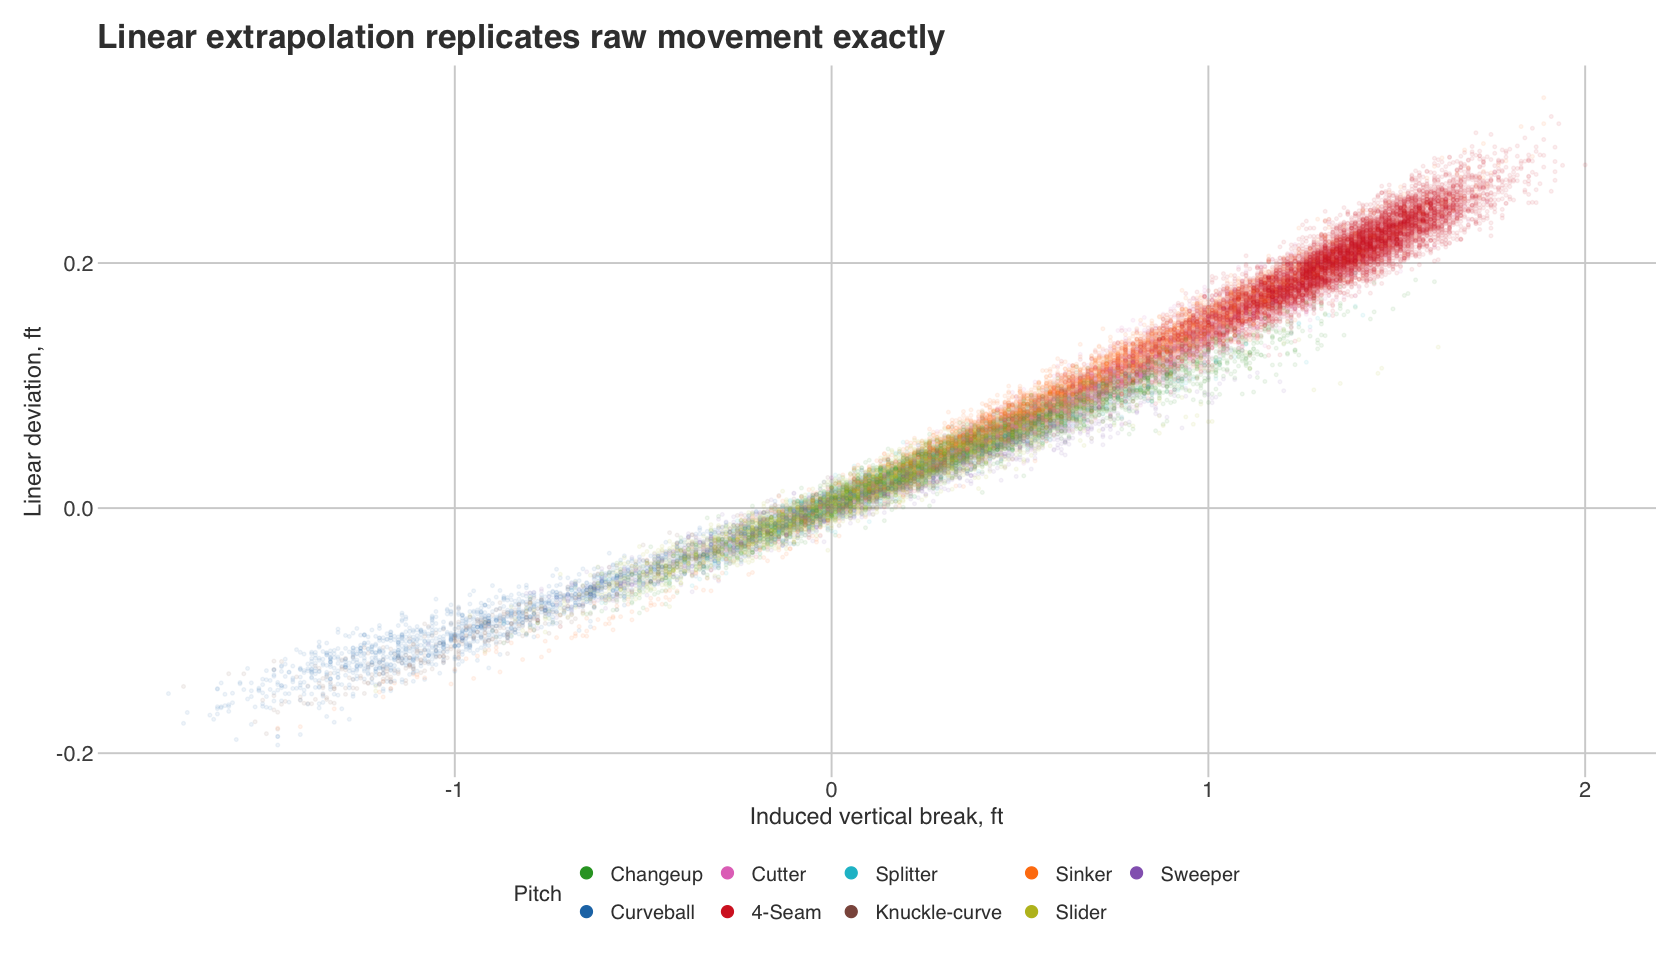

In [24]:
r_lin <- cor(pc_sample$pfx_z, pc_sample$pc150_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7) +
  scale_color_manual(values = PITCH_COLORS,
                     labels = PITCH_NAMES[names(PITCH_COLORS)],
                     name   = "Pitch") +
  labs(
    title = "Linear extrapolation replicates raw movement exactly",
    x        = "Induced vertical break, ft",
    y        = "Linear deviation, ft"
  ) +
  guides(color = guide_legend(override.aes = list(alpha = 1, size = 3)))

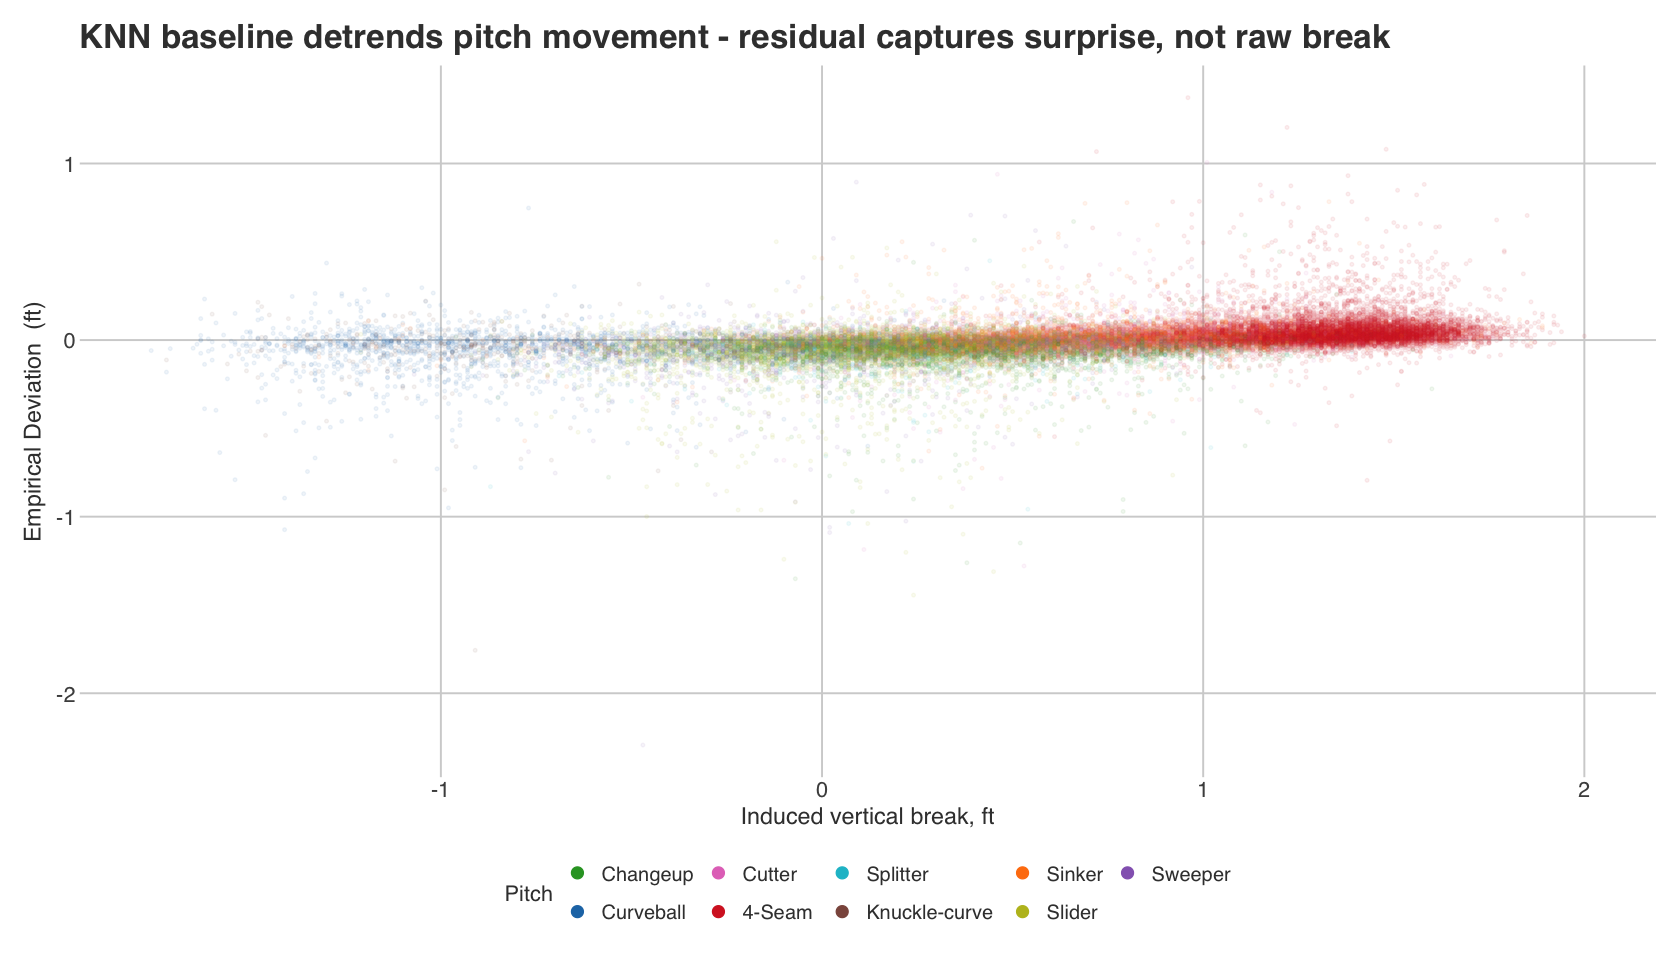

In [25]:
r_emp <- cor(pc_sample$pfx_z, pc_sample$pc150_emp_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_emp_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7) +
  scale_color_manual(values = PITCH_COLORS,
                     labels = PITCH_NAMES[names(PITCH_COLORS)],
                     name   = "Pitch") +
  labs(
    title = "KNN baseline detrends pitch movement - residual captures surprise, not raw break",
    x        = "Induced vertical break, ft",
    y        = "Empirical Deviation  (ft)"
  ) +
  guides(color = guide_legend(override.aes = list(alpha = 1, size = 3)))

## Why KNN Over Linear Trajectory?

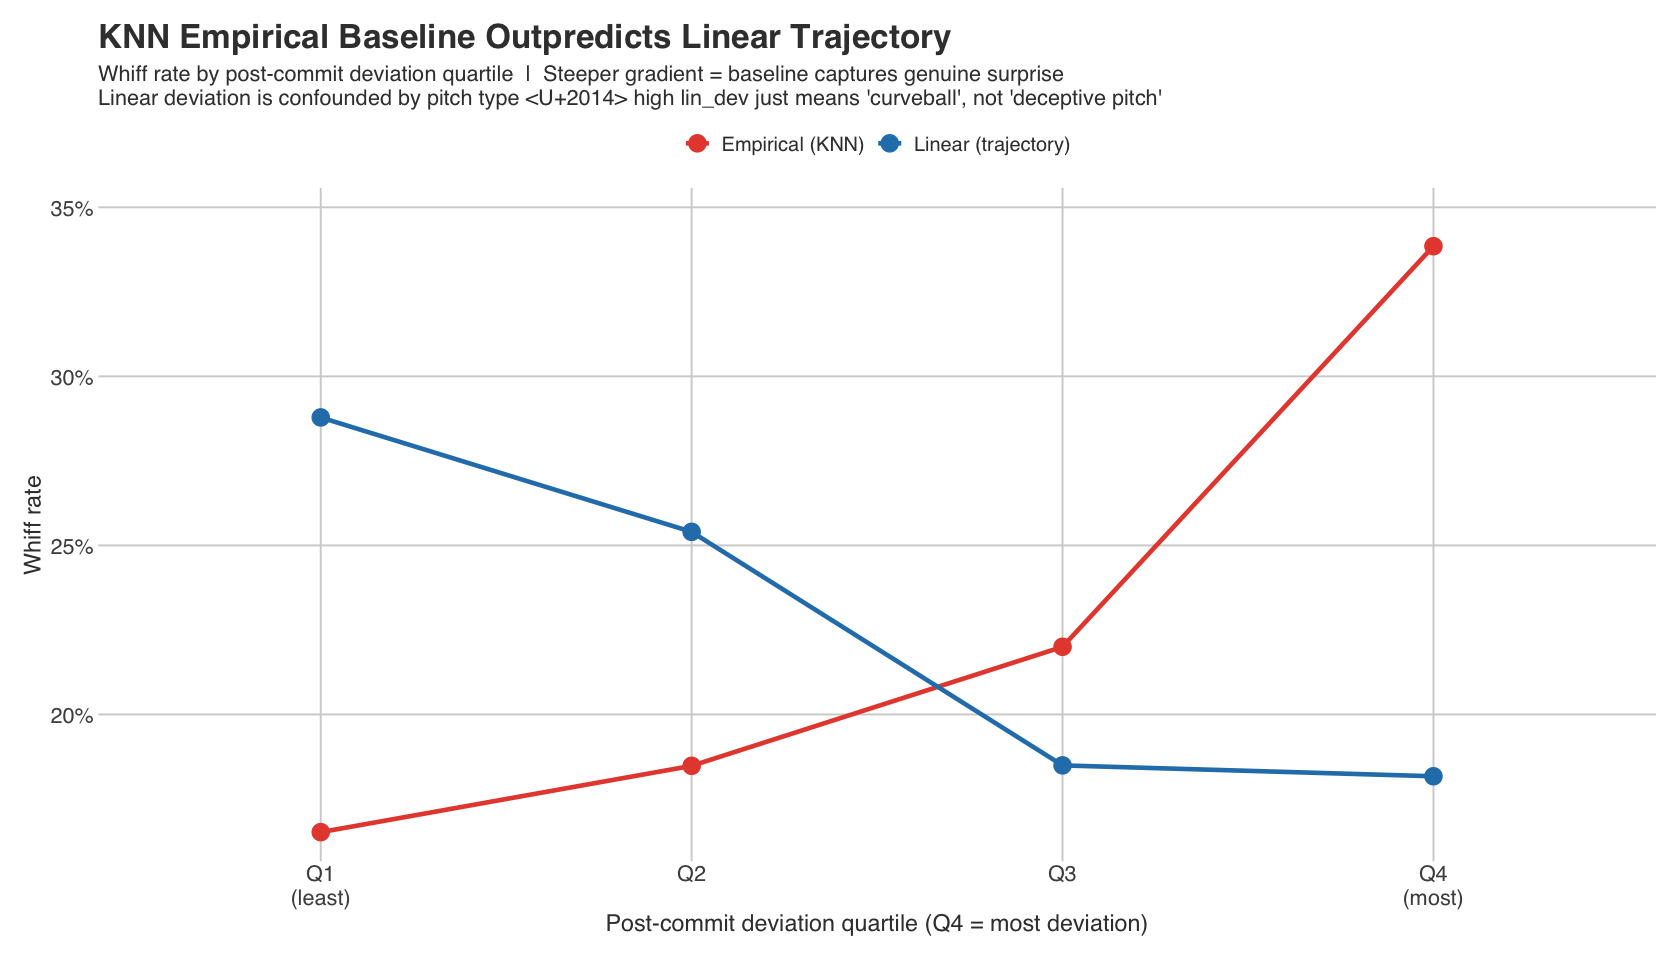

In [26]:
ggplot(pc_baseline_cmp,
       aes(x = quartile_label, y = whiff_rate,
           color = baseline, group = baseline)) +
  geom_line(linewidth = 1.3) +
  geom_point(size = 4.5) +
  scale_color_manual(
    values = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
    name   = NULL
  ) +
  scale_y_continuous(labels = percent_format(accuracy = 1),
                     expand = expansion(mult = c(0.05, 0.1))) +
  labs(
    title    = "KNN Empirical Baseline Outpredicts Linear Trajectory",
    subtitle = "Whiff rate by post-commit deviation quartile  |  Steeper gradient = baseline captures genuine surprise\nLinear deviation is confounded by pitch type — high lin_dev just means 'curveball', not 'deceptive pitch'",
    x        = "Post-commit deviation quartile (Q4 = most deviation)",
    y        = "Whiff rate"
  ) +
  theme(legend.position = "top")

## Deception Ratio by Pitch Type

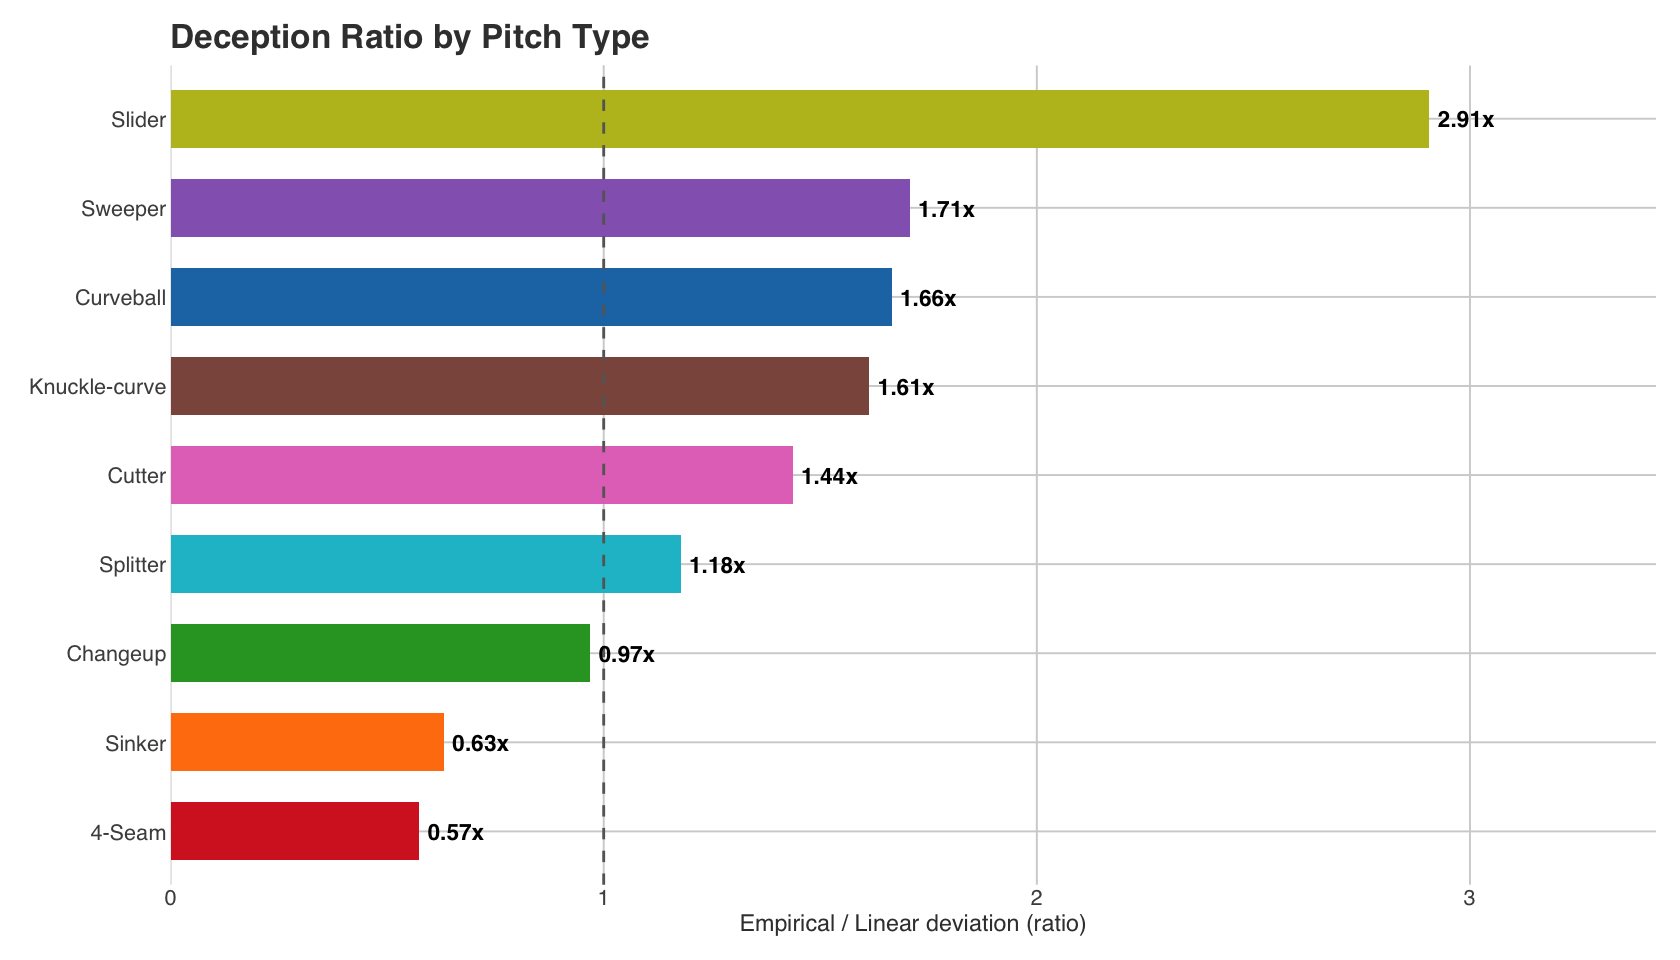

In [27]:
ggplot(pc_deception,
       aes(x = reorder(pitch_name, emp_lin_ratio),
           y = emp_lin_ratio, fill = pitch_type)) +
  geom_col(width = 0.65) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.2fx", emp_lin_ratio)),
            hjust = -0.15, size = 4.8, fontface = "bold") +
  scale_fill_manual(values = PITCH_COLORS, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
  coord_flip() +
  labs(
    title    = "Deception Ratio by Pitch Type",
    x        = NULL,
    y        = "Empirical / Linear deviation (ratio)"
  )

## KNN Bias-Variance: RMSE vs K

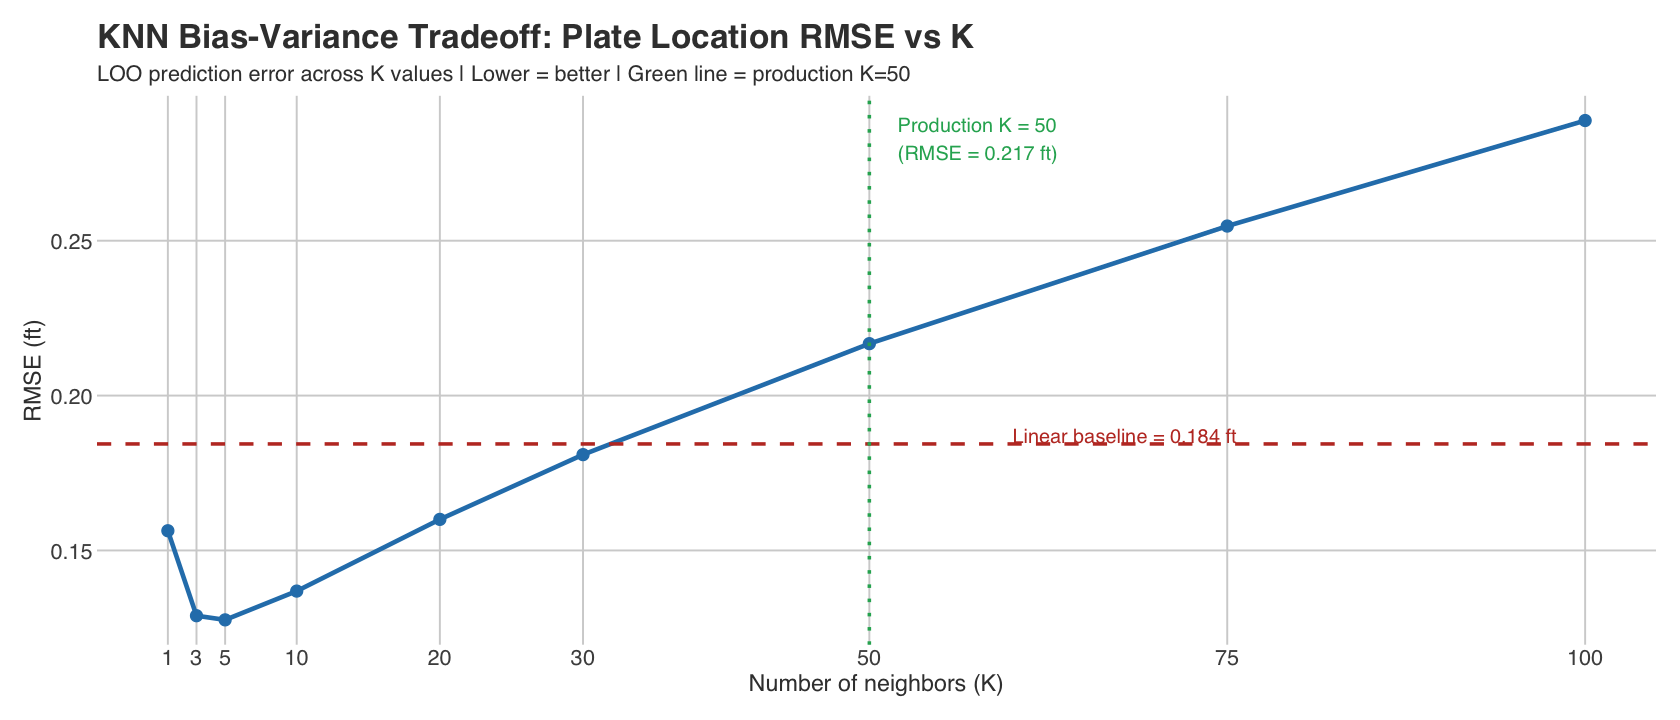

In [28]:
lin_rmse <- knn_k_sens$linear_rmse[1]
prod_k   <- 50L
prod_rmse <- knn_k_sens |> filter(k == prod_k) |> pull(rmse)

p_ksens <- ggplot(knn_k_sens, aes(x = k, y = rmse)) +
  geom_line(color = "#2980b9", linewidth = 1.3) +
  geom_point(color = "#2980b9", size = 3) +
  geom_hline(aes(yintercept = lin_rmse, linetype = "Linear baseline"),
             color = "#c0392b", linewidth = 1.0) +
  geom_vline(xintercept = prod_k, linetype = "dotted",
             color = "#27ae60", linewidth = 1.0) +
  annotate("text", x = prod_k + 2, y = max(knn_k_sens$rmse) * 0.98,
           label = sprintf("Production K = %d\n(RMSE = %.3f ft)", prod_k, prod_rmse),
           hjust = 0, size = 4.2, color = "#27ae60") +
  annotate("text", x = max(knn_k_sens$k) * 0.6, y = lin_rmse * 1.015,
           label = sprintf("Linear baseline = %.3f ft", lin_rmse),
           hjust = 0, size = 4.2, color = "#c0392b") +
  scale_linetype_manual(values = c("Linear baseline" = "dashed"), name = NULL) +
  scale_x_continuous(breaks = knn_k_sens$k) +
  labs(
    title    = "KNN Bias-Variance Tradeoff: Plate Location RMSE vs K",
    subtitle = "LOO prediction error across K values | Lower = better | Green line = production K=50",
    x        = "Number of neighbors (K)",
    y        = "RMSE (ft)"
  ) +
  theme(legend.position = "none")

options(repr.plot.width = 14, repr.plot.height = 6)
p_ksens
ggsave("results/plots/diagnostics/knn_k_sensitivity.png", p_ksens,
       width = 14, height = 6, dpi = 150)

## Why K=50? Deviation Spread by Pitch Type

The key diagnostic is whether the KNN baseline correctly recognizes each pitch type's typical late movement. If K is too small, the baseline overfits the specific pitches in the neighborhood and treats genuinely surprising movement as expected, compressing all deviations toward zero. The chart below shows that at K=50, 4-seamers (which ride up predictably) produce much smaller empirical deviations than the linear trajectory predicts, while sweepers and sliders produce larger empirical deviations. That reordering confirms the KNN baseline is pitch-type-aware: it correctly absorbs expected movement and passes only true post-commit surprise downstream. K=5 collapses all bars toward zero; K=50 sits in the stable zone where this differentiation persists without large RMSE inflation.

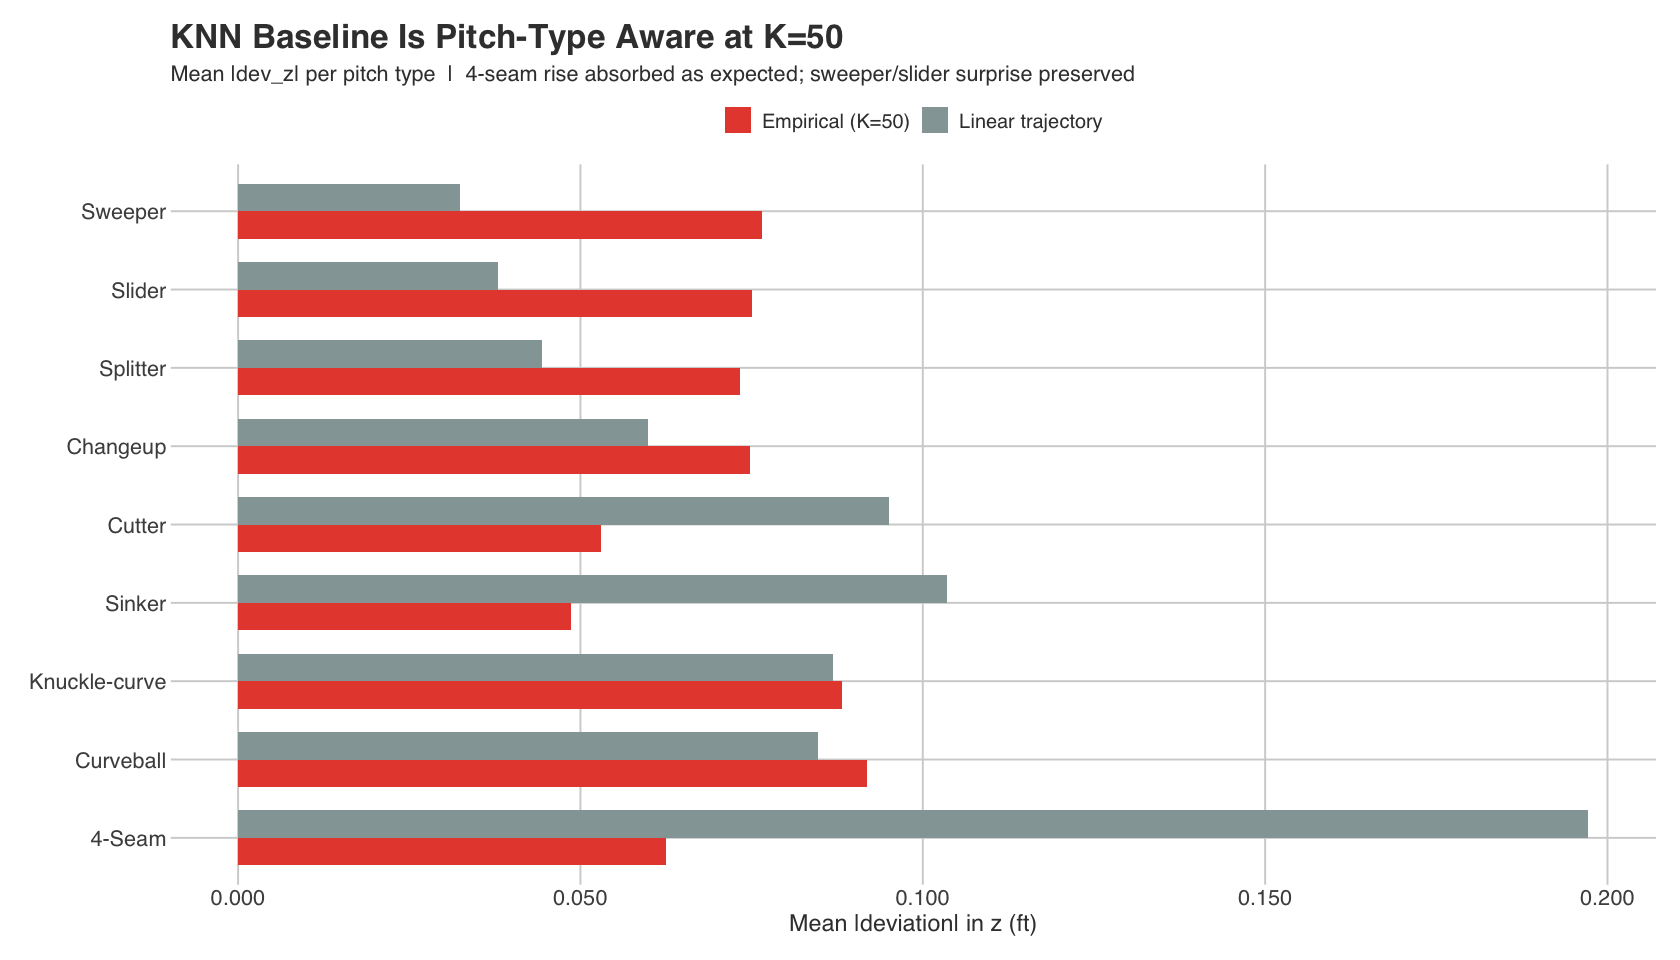

In [31]:
# Deviation spread: Empirical K=50 vs Linear by pitch type
spread_long <- knn_pt_spread |>
  select(pitch_name, pitch_type,
         `Empirical (K=50)` = mean_abs_emp_dev_z,
         `Linear trajectory` = mean_abs_lin_dev_z) |>
  pivot_longer(c(`Empirical (K=50)`, `Linear trajectory`),
               names_to = "baseline", values_to = "mean_abs_dev_z") |>
  mutate(baseline = factor(baseline, levels = c("Empirical (K=50)", "Linear trajectory")))

p_spread <- ggplot(spread_long,
                   aes(x = reorder(pitch_name, -mean_abs_dev_z),
                       y = mean_abs_dev_z,
                       fill = baseline)) +
  geom_col(position = "dodge", width = 0.7) +
  scale_fill_manual(
    values = c("Empirical (K=50)" = "#e74c3c", "Linear trajectory" = "#95a5a6"),
    name = NULL
  ) +
  scale_y_continuous(labels = function(x) sprintf("%.3f", x)) +
  coord_flip() +
  labs(
    title    = "KNN Baseline Is Pitch-Type Aware at K=50",
    subtitle = "Mean |dev_z| per pitch type  |  4-seam rise absorbed as expected; sweeper/slider surprise preserved",
    x = NULL, y = "Mean |deviation| in z (ft)"
  ) +
  theme(legend.position = "top")

options(repr.plot.width = 14, repr.plot.height = 8)
p_spread
ggsave("results/plots/diagnostics/k50_deviation_spread.png", p_spread,
       width = 14, height = 8, dpi = 300)


## Commit-Time Feature Space (PCA)

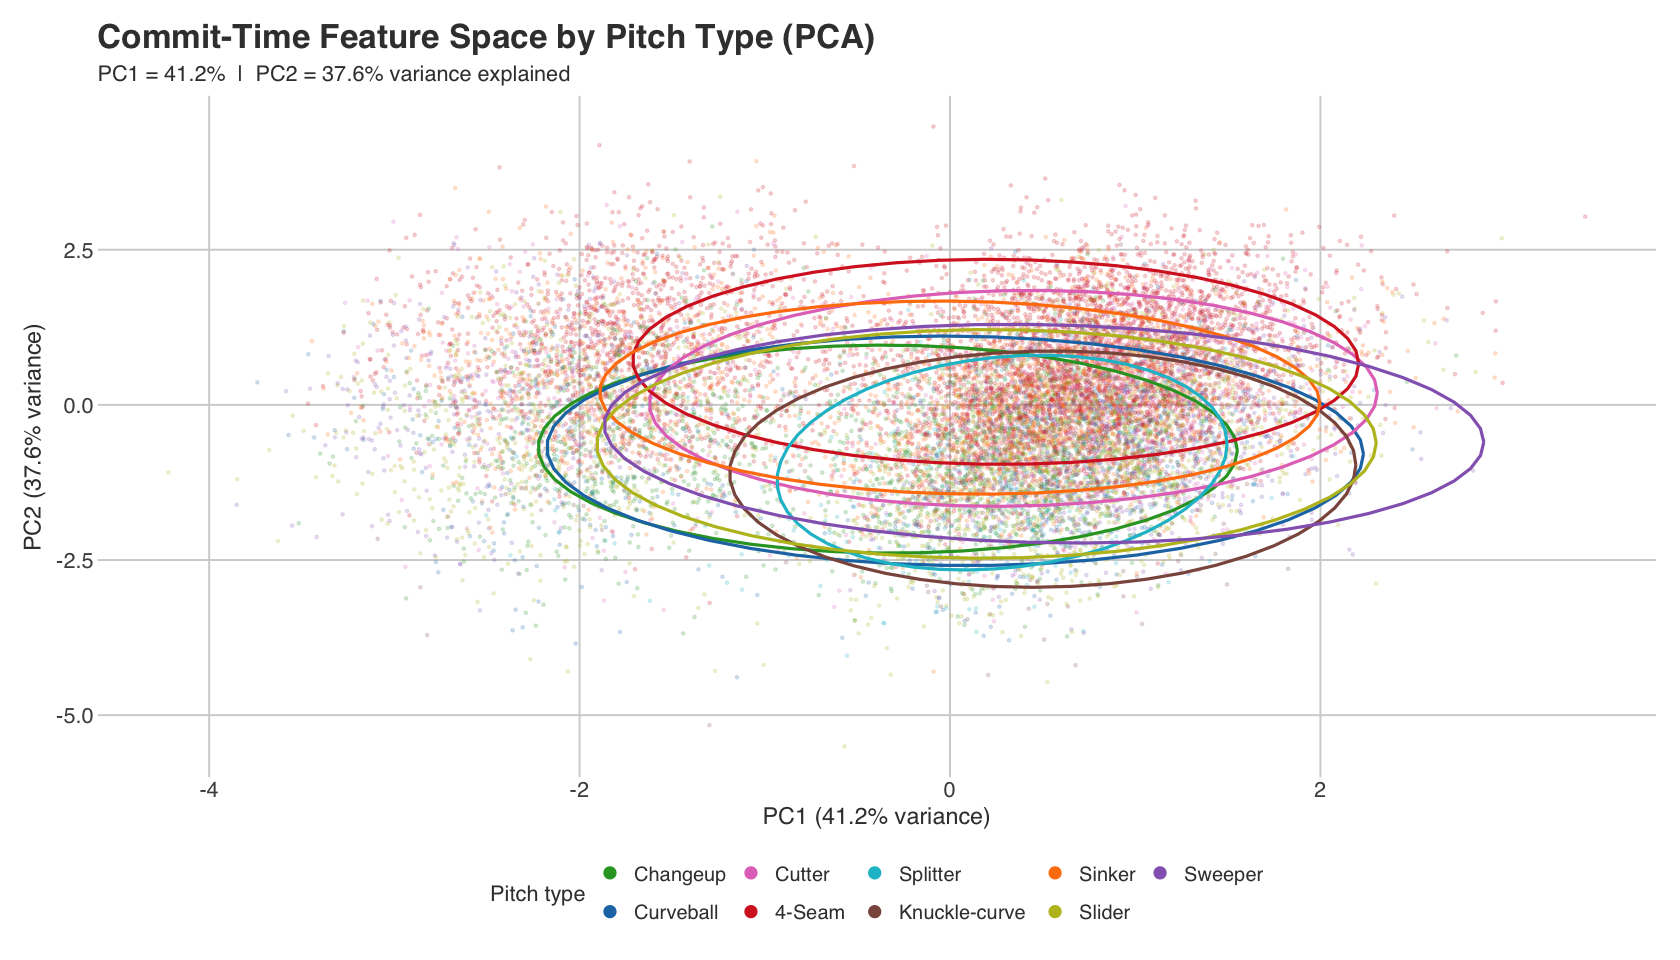

In [30]:
pc1_var <- round(knn_pca_var$var_explained[1] * 100, 1)
pc2_var <- round(knn_pca_var$var_explained[2] * 100, 1)

p_pca <- knn_pca |>
  filter(!is.na(pitch_name)) |>
  slice_sample(n = 15000) |>
  ggplot(aes(x = PC1, y = PC2, color = pitch_type)) +
  geom_point(alpha = 0.18, size = 0.6) +
  stat_ellipse(aes(group = pitch_type), level = 0.80,
               linewidth = 0.9, show.legend = FALSE) +
  scale_color_manual(values = PITCH_COLORS,
                     labels = PITCH_NAMES[names(PITCH_COLORS)],
                     name   = "Pitch type") +
  guides(color = guide_legend(override.aes = list(alpha = 1, size = 3))) +
  labs(
    title    = "Commit-Time Feature Space by Pitch Type (PCA)",
    subtitle = sprintf(
      "PC1 = %.1f%%  |  PC2 = %.1f%% variance explained ",
      pc1_var, pc2_var
    ),
    x = sprintf("PC1 (%.1f%% variance)", pc1_var),
    y = sprintf("PC2 (%.1f%% variance)", pc2_var)
  )

options(repr.plot.width = 14, repr.plot.height = 8)
p_pca
ggsave("results/plots/diagnostics/knn_pca.png", p_pca,
       width = 14, height = 8, dpi = 150)